In [194]:
from matplotlib.image import imread 
import matplotlib.pyplot as plt
import numpy as np
import time
import cv2

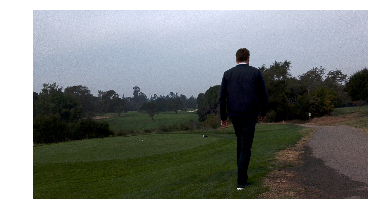

In [268]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz5/left0586.jpg')
plt.imshow(A)
plt.axis('off')
plt.savefig('1orig.jpg', dpi=100, bbox_inches='tight')
plt.show()

In [241]:
from skimage.data import astronaut
from skimage.color import rgb2gray
from skimage.filters import sobel
from skimage.segmentation import felzenszwalb, slic, quickshift, watershed
from skimage.segmentation import mark_boundaries
from skimage.util import img_as_float
from skimage import data, color
from skimage.transform import rescale, resize, downscale_local_mean, pyramid_reduce


Felzenszwalb number of segments: 185
SLIC number of segments: 233
Quickshift number of segments: 861
Watershed number of segments: 252


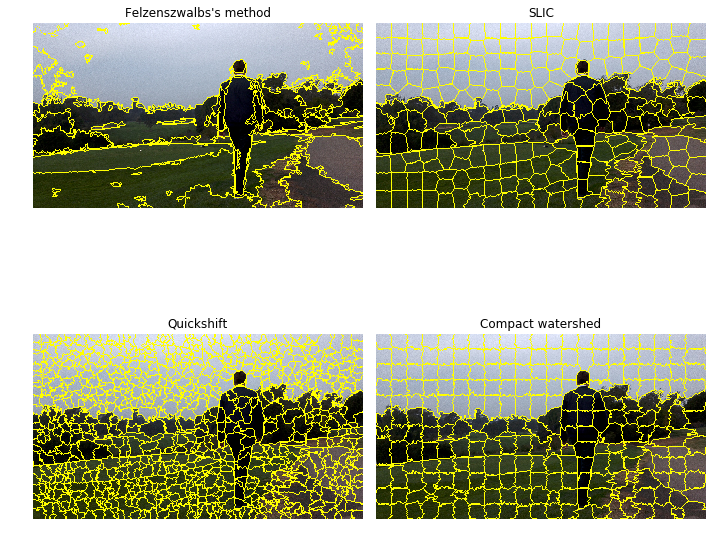

In [112]:
img = img_as_float(A[::2, ::2])

segments_fz = felzenszwalb(img, scale=100, sigma=0.5, min_size=50)
segments_slic = slic(img, n_segments=250, compactness=10, sigma=1)
segments_quick = quickshift(img, kernel_size=3, max_dist=6, ratio=0.5)
gradient = sobel(rgb2gray(img))
segments_watershed = watershed(gradient, markers=250, compactness=0.001)

print("Felzenszwalb number of segments: {}".format(len(np.unique(segments_fz))))
print('SLIC number of segments: {}'.format(len(np.unique(segments_slic))))
print('Quickshift number of segments: {}'.format(len(np.unique(segments_quick))))
print('Watershed number of segments: {}'.format(len(np.unique(segments_watershed))))
fig, ax = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)

ax[0, 0].imshow(mark_boundaries(img, segments_fz))
ax[0, 0].set_title("Felzenszwalbs's method")
ax[0, 1].imshow(mark_boundaries(img, segments_slic))
ax[0, 1].set_title('SLIC')
ax[1, 0].imshow(mark_boundaries(img, segments_quick))
ax[1, 0].set_title('Quickshift')
ax[1, 1].imshow(mark_boundaries(img, segments_watershed))
ax[1, 1].set_title('Compact watershed')

for a in ax.ravel():
    a.set_axis_off()

plt.tight_layout()
plt.show()

0.09364710500085494
Felzenszwalb number of segments: 9


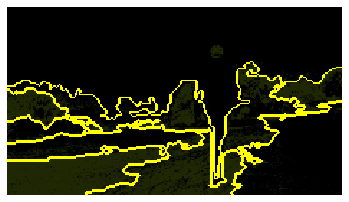

In [302]:
A = imread('1pred.jpg')
start = time.perf_counter()
A = pyramid_reduce(A)
img = img_as_float(A[::2, ::2])

segments_fz = felzenszwalb(img, scale=100, sigma=0.701, min_size=500)
print(time.perf_counter()-start)
print("Felzenszwalb number of segments: {}".format(len(np.unique(segments_fz))))
fig = plt.imshow(mark_boundaries(img, segments_fz))
plt.axis('off')
fig.axes.get_xaxis().set_visible(False)
fig.axes.get_yaxis().set_visible(False)
plt.savefig('1pred_bound.png', dpi=100, bbox_inches='tight', pad_inches=0)
plt.show()


In [196]:
np.random.seed(14) 
m1,m2,n = A.shape 
K = 32 
mu = np.zeros((3,K)) 
for i in range(K): 
    x1 = np.random.randint(0,m1) 
    x2 = np.random.randint(0,m2) 
    mu[:,i] = A[x1,x2,:] 
it = 0 
prev_mu = None 
while it < 9 and (prev_mu is None or np.abs(ll)>=0.5): 
    prev_mu = np.linalg.norm(mu) 
    it +=1 
    print(it) 
    arg = np.zeros((K)) 
    c = np.zeros((m1,m2)) 
    mean = np.zeros((m1,m2,K)) 
    for l in range(K): 
        mu_b = np.broadcast_to(mu[:,l],(m1,m2,n)) 
        A_new = A.flatten() 
        mu_new = mu_b.flatten() 
        diff = A_new-mu_new 
        diff = np.square(diff) 
        mean[:,:,l] = np.sum(diff.reshape(m1,m2,n),axis=2) 
        argmin = np.argmin(mean,axis=2) 
        indices = np.zeros((m1,m2,K)) 
    for j in range(K): 
        a= argmin==j 
        indices[:,:,j] = a.astype(int) 
        mu[:,j] = np.sum(np.sum(indices[:,:,j].T*(A.T),axis=2),axis=1)/np.sum(indices[:,:,j])
    ll =prev_mu-np.linalg.norm(mu) 
    print(ll)

1
-2.6993223218794355
2
-1.3951475808626128
3
-0.567708831904838
4
-0.45279796491195157


In [197]:
threshold = 1000

20


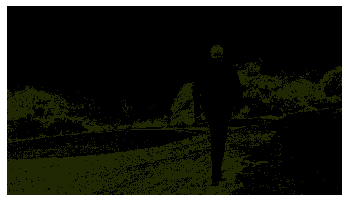

0.0751185320004879


In [269]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('1pred.jpg', dpi=200, bbox_inches='tight', pad_inches=0)
    plt.show()
print((end-start))

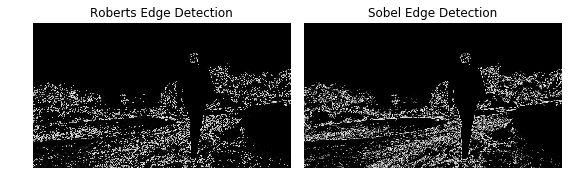

In [183]:
from skimage.data import camera
from skimage.filters import roberts, sobel, scharr, prewitt


image = cv2.imread('1pred.jpg',0)
edge_roberts = roberts(image)
edge_sobel = sobel(image)

fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True,
                       figsize=(8, 4))

ax[0].imshow(edge_roberts, cmap=plt.cm.gray)
ax[0].set_title('Roberts Edge Detection')

ax[1].imshow(edge_sobel, cmap=plt.cm.gray)
ax[1].set_title('Sobel Edge Detection')

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

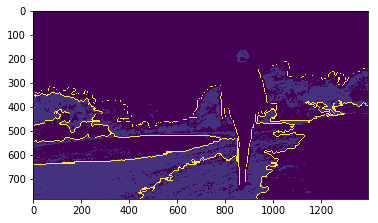

In [182]:
new_image = cv2.imread('1pred.png',0)
dst = new_image
kernel = np.ones((3,3),np.float32)/9
for i in range(2):
    dst = cv2.medianBlur(dst,ksize=3)
#sobelx = cv2.Sobel(new_image,cv2.CV_64F,1,0,ksize=5)
#sobely = cv2.Sobel(new_image,cv2.CV_64F,0,1,ksize=5)
#sob = np.hypot(sobelx,sobely)
plt.imshow(dst)
#plt.imshow(laplacian,cmap = 'gray')

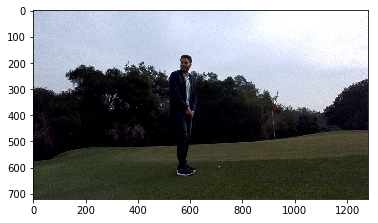

In [159]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz6/left22156.jpg')
plt.imshow(A)
plt.savefig('2orig.png', format='png', dpi=1000)
plt.show()

20


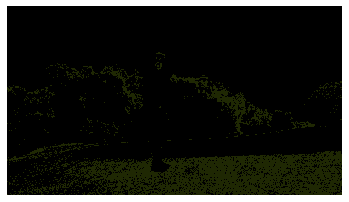

0.08227388599880214


In [15]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('2pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

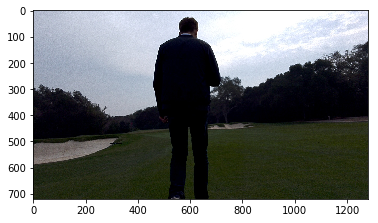

In [89]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz6/left21281.jpg')
plt.imshow(A)
plt.savefig('3orig.png', format='png', dpi=1000)
plt.show()

20


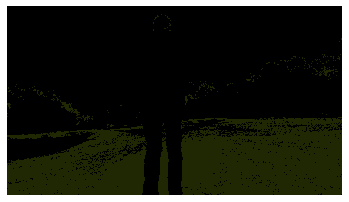

0.07593823400020483


In [17]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('3pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

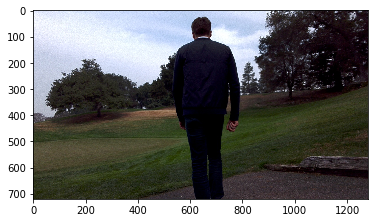

In [91]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz6/left27138.jpg')
plt.imshow(A)
plt.savefig('4orig.png', format='png', dpi=1000)
plt.show()

20


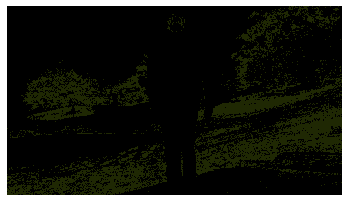

0.08959555899855332


In [19]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('4pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

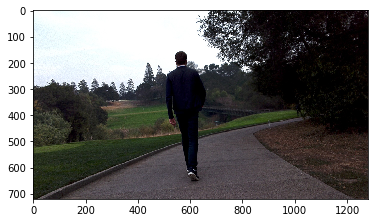

In [99]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz6/left24720.jpg')
plt.imshow(A)
plt.savefig('5orig.png', format='png', dpi=1000)
plt.show()

20


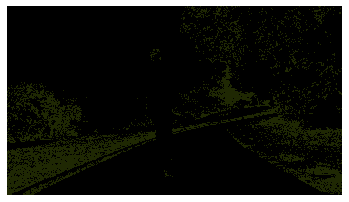

0.07646949400077574


In [21]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('5pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

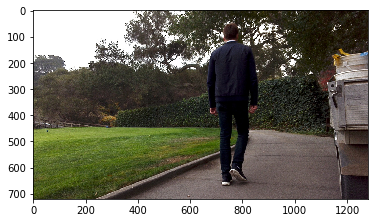

In [101]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz6/left25196.jpg')
plt.imshow(A)
plt.savefig('6orig.png', format='png', dpi=1000)
plt.show()

20


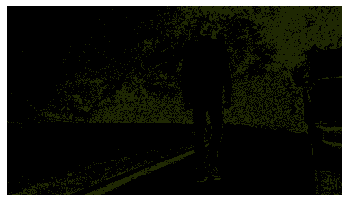

0.09300891599923489


In [23]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('6pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

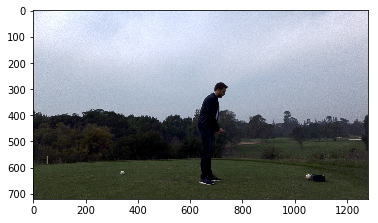

In [103]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz7/left0445.jpg')
plt.imshow(A)
plt.savefig('7orig.png', format='png', dpi=1000)
plt.show()

20


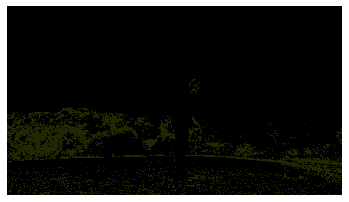

0.07776411299892061


In [25]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('7pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))

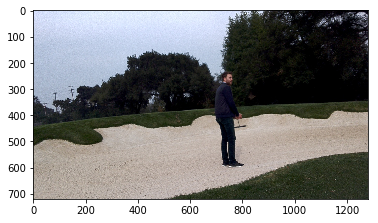

In [105]:
A = imread('/home/oxjay/Downloads/Untitled Folder/picz8/left9236.jpg')
plt.imshow(A)
plt.savefig('8orig.png', format='png', dpi=1000)
plt.show()

20


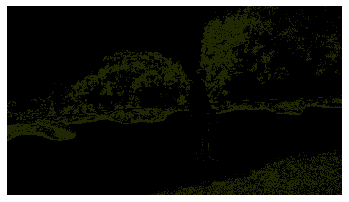

0.11769147000086377


In [27]:
indices = np.zeros((m1,m2))
start=time.perf_counter()
for l in range(20,21):
    mu_b = np.broadcast_to(mu[:,l],(m1,m2,n))
    print(l)
    A_new = A.flatten()
    mu_new = mu_b.flatten()
    diff = A_new-mu_new
    diff = np.square(diff)
    diff = np.sum(diff.reshape(m1,m2,n),axis=2)
    a= diff<=threshold
    indices[:,:] = a.astype(int)
    new_image = np.ones((m1,m2,n))
    new_image = indices.T*(mu[:,l]*new_image).T
    new_image = np.round(new_image.T)
    new_image = new_image.astype(int)
    end = time.perf_counter()
    plt.imshow(new_image)
    fig = plt.imshow(new_image)
    plt.axis('off')
    fig.axes.get_xaxis().set_visible(False)
    fig.axes.get_yaxis().set_visible(False)
    plt.savefig('8pred.png', format='png', dpi=1000)
    plt.show()
print((end-start))